# Book-Crossing Recommender System
## Data Mining Lab Assignment — Medallion Data Lake

This notebook builds an end-to-end **Bronze → Silver → Gold** pipeline from the Book-Crossing dataset and uses the Gold data to create an **item-based collaborative-filtering recommender**.

**Run the notebook from top to bottom in Google Colab.** The raw ZIP is downloaded automatically. All generated Parquet files and the sparse matrix are written into the project folders created by this notebook.

### Pipeline overview
1. **Bronze:** read the three source CSV files without cleaning, add an ingestion timestamp, and save Parquet copies.
2. **EDA:** profile table shapes, data types, missing values, rating distribution, age/year anomalies, activity counts, and sparsity.
3. **Silver:** remove duplicates, clean fields, discard non-explicit ratings, enforce valid relationships, and apply a minimum-activity threshold.
4. **Gold:** create a sparse book-by-user rating matrix, readable book/user lookup tables, and aggregates.
5. **Model:** use cosine similarity between book vectors to find similar books and recommend unseen books to users.
6. **Demo:** run recommendations for three users and check that already-rated books are not recommended.

> The source ratings use `0` for an implicit interaction rather than an explicit preference. Only ratings from `1` to `10` are used by the recommender.

## Before you run

- Open this `.ipynb` file in **Google Colab**.
- Select **Runtime → Run all**.
- The first code cell installs any missing Python packages.
- The dataset is about 25 MB and is downloaded automatically by the ingestion step.
- The data lake is created under `/content/book_crossing_medallion/` in Colab. Runtime files are temporary, so download or save any outputs you need before closing the session.

No manual CSV upload or path editing is needed.

In [5]:
# Install only the packages that are not already available in this runtime.
from importlib.util import find_spec
import subprocess
import sys

packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "scipy": "scipy",
    "sklearn": "scikit-learn",
    "matplotlib": "matplotlib",
    "pyarrow": "pyarrow",
}

missing_packages = [
    package_name
    for module_name, package_name in packages.items()
    if find_spec(module_name) is None
]

if missing_packages:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", *missing_packages]
    )

print("Package check complete.")

Package check complete.


In [6]:
from pathlib import Path
from zipfile import ZipFile, is_zipfile
from urllib.request import urlretrieve
from shutil import copyfileobj
from datetime import datetime, timezone
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, HTML
from scipy.sparse import csr_matrix, save_npz, load_npz
from sklearn.neighbors import NearestNeighbors

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)

# Use a predictable project directory in Colab; remain usable in Jupyter as well.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

PROJECT_ROOT = (
    Path("/content/book_crossing_medallion")
    if IN_COLAB
    else Path.cwd() / "book_crossing_medallion"
)

RAW_DIR = PROJECT_ROOT / "data" / "raw"
BRONZE_DIR = PROJECT_ROOT / "bronze"
SILVER_DIR = PROJECT_ROOT / "silver"
GOLD_DIR = PROJECT_ROOT / "gold"

for folder in [RAW_DIR, BRONZE_DIR, SILVER_DIR, GOLD_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

DATA_URL = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
ARCHIVE_PATH = RAW_DIR / "book-crossings.zip"

print("Project directory:", PROJECT_ROOT)
print("Created folders:", [BRONZE_DIR.name, SILVER_DIR.name, GOLD_DIR.name])

Project directory: /content/book_crossing_medallion
Created folders: ['bronze', 'silver', 'gold']


## Step 1 — Build the Bronze layer

The source archive contains `BX-Users.csv`, `BX-Books.csv`, and `BX-Book-Ratings.csv`. These files are semicolon-separated and use a Latin-1-compatible encoding.

Bronze keeps the source columns and values as read. The **only additional field** is `ingestion_timestamp`; no rows or columns are cleaned or removed here.

In [7]:
import urllib.request

# Download the source archive once, then extract only the three expected CSV files.
if not ARCHIVE_PATH.exists() or not is_zipfile(ARCHIVE_PATH):
    if ARCHIVE_PATH.exists():
        ARCHIVE_PATH.unlink()
    print("Downloading Book-Crossing data...")

    # Use a custom User-Agent to prevent 403 Forbidden response from CDNs
    req = urllib.request.Request(
        DATA_URL,
        headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36'}
    )
    with urllib.request.urlopen(req) as response, open(ARCHIVE_PATH, 'wb') as out_file:
        copyfileobj(response, out_file)

expected_files = {
    "users": "BX-Users.csv",
    "books": "BX-Books.csv",
    "ratings": "BX-Book-Ratings.csv",
}

with ZipFile(ARCHIVE_PATH, "r") as archive:
    archive_names = archive.namelist()

    for table_name, expected_name in expected_files.items():
        match = next(
            (member for member in archive_names
             if Path(member).name == expected_name),
            None,
        )
        if match is None:
            raise FileNotFoundError(
                f"{expected_name} was not found inside {ARCHIVE_PATH.name}."
            )

        output_path = RAW_DIR / expected_name
        with archive.open(match) as source_file, output_path.open("wb") as target_file:
            copyfileobj(source_file, target_file)

# Read the original files with the correct delimiter and encoding.
bronze_tables = {}
ingestion_time = pd.Timestamp.now(tz="UTC")

for table_name, file_name in expected_files.items():
    csv_path = RAW_DIR / file_name

    table = pd.read_csv(
        csv_path,
        sep=";",
        encoding="latin-1",
        escapechar="\\",
        low_memory=False,
    )

    # Do not clean the source data in Bronze.
    table["ingestion_timestamp"] = ingestion_time
    parquet_path = BRONZE_DIR / f"{table_name}.parquet"
    table.to_parquet(parquet_path, index=False)

    bronze_tables[table_name] = table
    print(
        f"{table_name:>7}: {table.shape[0]:,} rows % {table.shape[1]} columns "
        f"→ {parquet_path.name}"
    )

users_bronze = bronze_tables["users"]
books_bronze = bronze_tables["books"]
ratings_bronze = bronze_tables["ratings"]

print("\nBronze ingestion completed.")

  users: 278,858 rows % 4 columns → users.parquet
  books: 271,379 rows % 9 columns → books.parquet
ratings: 1,149,780 rows % 4 columns → ratings.parquet

Bronze ingestion completed.


## Step 2 — Explore the Bronze layer

The next cell reads the Bronze Parquet files back, then reports each table's dimensions, data types, and missing-value counts. It also calculates the rating, age, publication-year, user-activity, book-activity, and matrix-sparsity distributions.


USERS — shape: (278858, 4)


,data_type,missing_count,missing_percent
User-ID,int64,0,0.00
Location,object,0,0.00
Age,float64,110762,39.72
ingestion_timestamp,"datetime64[us, UTC]",0,0.00


Exact duplicate rows: 0

BOOKS — shape: (271379, 9)


,data_type,missing_count,missing_percent
ISBN,object,0,0.0
Book-Title,object,0,0.0
Book-Author,object,2,0.0
Year-Of-Publication,int64,0,0.0
Publisher,object,2,0.0
Image-URL-S,object,0,0.0
Image-URL-M,object,0,0.0
Image-URL-L,object,0,0.0
ingestion_timestamp,"datetime64[us, UTC]",0,0.0


Exact duplicate rows: 0

RATINGS — shape: (1149780, 4)


,data_type,missing_count,missing_percent
User-ID,int64,0,0.0
ISBN,object,0,0.0
Book-Rating,int64,0,0.0
ingestion_timestamp,"datetime64[us, UTC]",0,0.0


... (5 outputs left out)

,Year-Of-Publication
count,271379.000000
mean,1959.756050
std,258.011363
min,0.000000
25%,1989.000000
50%,1995.000000
75%,2000.000000
max,2050.000000


Missing/non-numeric years: 0
Year zero: 4619
Years later than 2026: 11

Ratings per user and per book:


,ratings_per_user,ratings_per_book
minimum,1.0,1.0
median,1.0,1.0
maximum,13602.0,2502.0


Possible user-book pairs: 75,676,205,182
Observed unique pairs: 1,149,780
Matrix density: 0.001519%
Matrix sparsity: 99.998481%


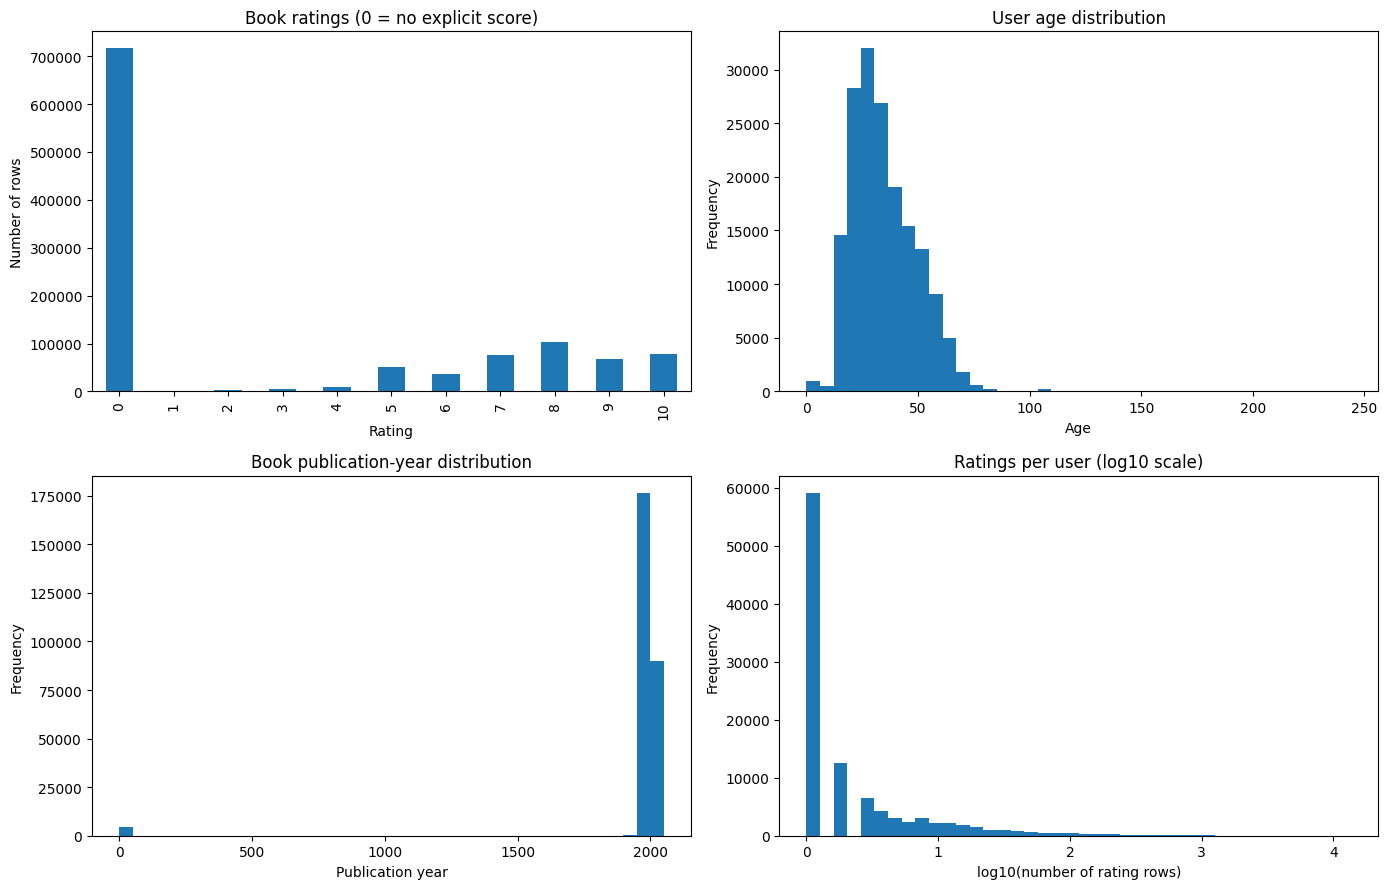

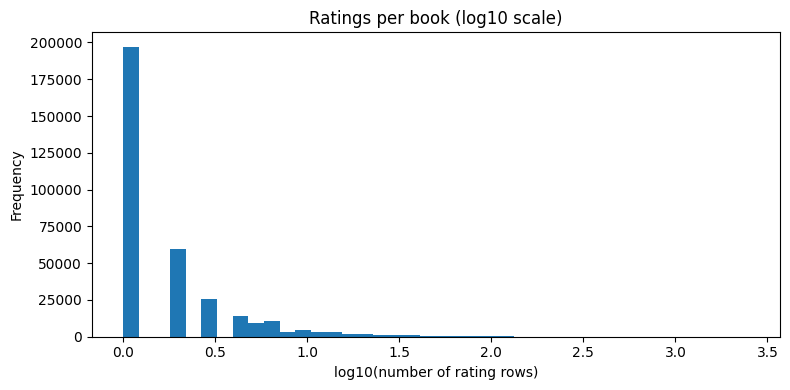

In [8]:
# Read the saved Bronze files back from Parquet before performing EDA.
bronze_tables = {
    table_name: pd.read_parquet(BRONZE_DIR / f"{table_name}.parquet")
    for table_name in expected_files
}

users_bronze = bronze_tables["users"]
books_bronze = bronze_tables["books"]
ratings_bronze = bronze_tables["ratings"]

for table_name, table in bronze_tables.items():
    profile = pd.DataFrame({
        "data_type": table.dtypes.astype(str),
        "missing_count": table.isna().sum(),
        "missing_percent": (table.isna().mean() * 100).round(2),
    })

    print(f"\n{table_name.upper()} — shape: {table.shape}")
    display(profile)
    duplicate_count = table.drop(columns=["ingestion_timestamp"]).duplicated().sum()
    print(f"Exact duplicate rows: {duplicate_count:,}")

# Rating distribution. A zero is an interaction without an explicit score.
rating_distribution = (
    ratings_bronze["Book-Rating"]
    .value_counts(dropna=False)
    .sort_index()
)
print("\nRating distribution (including zero):")
display(rating_distribution.to_frame("number_of_rows"))
print(
    "Zero ratings:",
    f"{int((ratings_bronze['Book-Rating'] == 0).sum()):,}",
    "of",
    f"{len(ratings_bronze):,}",
)

# Age and publication-year checks.
age_values = pd.to_numeric(users_bronze["Age"], errors="coerce")
year_values = pd.to_numeric(
    books_bronze["Year-Of-Publication"], errors="coerce"
)

print("\nUser age summary:")
display(age_values.describe(percentiles=[0.25, 0.50, 0.75]).to_frame("Age"))
print("Missing ages:", int(age_values.isna().sum()))
print("Ages below 5:", int((age_values < 5).sum()))
print("Ages above 100:", int((age_values > 100).sum()))

current_year = datetime.now().year
print("\nPublication-year summary:")
display(year_values.describe().to_frame("Year-Of-Publication"))
print("Missing/non-numeric years:", int(year_values.isna().sum()))
print("Year zero:", int((year_values == 0).sum()))
print(f"Years later than {current_year}:", int((year_values > current_year).sum()))

# Rating activity counts are calculated on all raw rating rows, including zeros.
ratings_per_user = ratings_bronze.groupby("User-ID").size()
ratings_per_book = ratings_bronze.groupby("ISBN").size()

def count_summary(series):
    return pd.Series({
        "minimum": int(series.min()),
        "median": float(series.median()),
        "maximum": int(series.max()),
    })

activity_summary = pd.DataFrame({
    "ratings_per_user": count_summary(ratings_per_user),
    "ratings_per_book": count_summary(ratings_per_book),
})
print("\nRatings per user and per book:")
display(activity_summary)

# Matrix density is the fraction of all possible user/book pairs that are observed.
possible_pairs = (
    users_bronze["User-ID"].nunique()
    * books_bronze["ISBN"].nunique()
)
observed_pairs = (
    ratings_bronze[["User-ID", "ISBN"]].drop_duplicates().shape[0]
)
matrix_density_percent = (
    observed_pairs / possible_pairs * 100 if possible_pairs else 0
)
matrix_sparsity_percent = 100 - matrix_density_percent

print(f"Possible user-book pairs: {possible_pairs:,}")
print(f"Observed unique pairs: {observed_pairs:,}")
print(f"Matrix density: {matrix_density_percent:.6f}%")
print(f"Matrix sparsity: {matrix_sparsity_percent:.6f}%")

# Visual checks for the important distributions.
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

rating_distribution.plot(
    kind="bar",
    ax=axes[0, 0],
    title="Book ratings (0 = no explicit score)",
    xlabel="Rating",
    ylabel="Number of rows",
)

age_values.dropna().plot(
    kind="hist",
    bins=40,
    ax=axes[0, 1],
    title="User age distribution",
    xlabel="Age",
)

year_values.dropna().plot(
    kind="hist",
    bins=40,
    ax=axes[1, 0],
    title="Book publication-year distribution",
    xlabel="Publication year",
)

np.log10(ratings_per_user.clip(lower=1)).plot(
    kind="hist",
    bins=40,
    ax=axes[1, 1],
    title="Ratings per user (log10 scale)",
    xlabel="log10(number of rating rows)",
)

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
np.log10(ratings_per_book.clip(lower=1)).plot(
    kind="hist",
    bins=40,
    ax=ax,
    title="Ratings per book (log10 scale)",
    xlabel="log10(number of rating rows)",
)
plt.tight_layout()
plt.show()

### EDA findings and decisions for Silver

The following observations are for the supplied Book-Crossing dump. The EDA cell above prints the exact counts again when the notebook is run.

| EDA item | What the data shows | Silver decision |
|---|---|---|
| Table shape, types, and missing values | Bronze contains **278,858 users**, **271,379 books**, and **1,149,780 ratings** (each with the added timestamp). User age is missing for **110,762** users; the books table has **2** missing author values and **2** missing publisher values; the ratings table has no missing key/rating values. | Keep Bronze unchanged. In Silver, clean data types and text; retain books with incomplete optional metadata rather than deleting otherwise useful ratings. |
| Rating distribution | There are **716,109 zero ratings** (about **62.28%** of all rating rows); explicit ratings use values from 1 to 10. | Drop rating `0` and keep only explicit ratings from `1` through `10`. |
| User ages and publication years | There are **882** ages below 5 and **366** above 100. Publication year `0` occurs **4,619** times and **11** years are later than 2026. | Convert invalid ages to null and fill them with the median valid age; convert year `0` and future publication years to null. |
| Ratings per user and per book | Raw activity is highly skewed: the median is **1 rating per user** and **1 rating per book**, while the maxima are **13,602** and **2,502**. | Keep users and books with at least **10 explicit ratings**. This removes entities with too little collaborative evidence while keeping a workable subset. |
| User-book matrix sparsity | There are **75,676,205,182** possible pairs but only **1,149,780** observed pairs: density is about **0.001519%** (sparsity about **99.998481%**). | Build the Gold matrix as a SciPy sparse matrix; do not create a dense user-by-book DataFrame. |

**Chosen threshold: 10 ratings per user and per book.** It is applied iteratively after zero ratings and invalid relationships are removed, so both sides of the final rating table meet the threshold.

## Step 3 — Clean the data and build the Silver layer

Silver applies the cleaning rules while leaving Bronze unchanged:

- Remove exact duplicate rows and resolve duplicate user/book identifiers.
- Replace invalid ages with the median valid age.
- Split `Location` into `City`, `State`, and `Country`.
- Clean text whitespace and standardize names/titles to title case.
- Set publication year `0` or a future year to null.
- Drop the three image URL columns.
- Keep only explicit ratings from 1 to 10 and only ratings whose user and ISBN exist.
- Average any repeated user-book pair left after exact duplicate removal.
- Iteratively enforce the chosen minimum of 10 ratings per user and per book.

In [9]:
def clean_text_column(series, title_case=True):
    """Trim whitespace, collapse repeated spaces, and optionally title-case text."""
    cleaned = (
        series.astype("string")
        .str.replace(r"\\s+", " ", regex=True)
        .str.strip()
        .replace("", pd.NA)
    )
    return cleaned.str.title() if title_case else cleaned


# Start from Bronze copies, not from the source CSV files.
users = (
    users_bronze.drop(columns=["ingestion_timestamp"])
    .drop_duplicates()
    .copy()
)
books = (
    books_bronze.drop(columns=["ingestion_timestamp"])
    .drop_duplicates()
    .copy()
)
ratings = (
    ratings_bronze.drop(columns=["ingestion_timestamp"])
    .drop_duplicates()
    .copy()
)

# ------------------------- Clean users -------------------------
users["User-ID"] = pd.to_numeric(users["User-ID"], errors="coerce")
users = users.dropna(subset=["User-ID"]).copy()
users["User-ID"] = users["User-ID"].astype("int64")
users = users.drop_duplicates(subset=["User-ID"], keep="first")

users["Age"] = pd.to_numeric(users["Age"], errors="coerce")
users.loc[~users["Age"].between(5, 100), "Age"] = np.nan
median_age = users["Age"].median()

if pd.isna(median_age):
    raise ValueError("No valid ages remain; median-age imputation is not possible.")

users["Age"] = users["Age"].fillna(median_age)

location = clean_text_column(users["Location"], title_case=False)
location_parts = location.str.split(",", n=2, expand=True).reindex(columns=[0, 1, 2])

users["City"] = clean_text_column(location_parts[0])
users["State"] = clean_text_column(location_parts[1])
users["Country"] = clean_text_column(location_parts[2])

# Keep short region/country codes uppercase (e.g. CA, USA); title-case full names.
for location_column in ["State", "Country"]:
    short_value = users[location_column].str.len().le(3)
    users.loc[short_value.fillna(False), location_column] = (
        users.loc[short_value.fillna(False), location_column].str.upper()
    )

users = users.drop(columns=["Location"])

# ------------------------- Clean books -------------------------
books["ISBN"] = (
    books["ISBN"].astype("string").str.strip().str.upper().replace("", pd.NA)
)
books = books.dropna(subset=["ISBN"]).copy()

for text_column in ["Book-Title", "Book-Author", "Publisher"]:
    if text_column in books.columns:
        books[text_column] = clean_text_column(books[text_column])

books["Year-Of-Publication"] = pd.to_numeric(
    books["Year-Of-Publication"], errors="coerce"
)
invalid_year = (
    books["Year-Of-Publication"].eq(0)
    | books["Year-Of-Publication"].gt(current_year)
)
books.loc[invalid_year, "Year-Of-Publication"] = np.nan

image_columns = [
    column for column in books.columns
    if column.startswith("Image-URL")
]
books = books.drop(columns=image_columns)

# One metadata record per ISBN: retain the row with the most non-null fields.
books["_metadata_completeness"] = books.notna().sum(axis=1)
books = (
    books.sort_values(
        "_metadata_completeness",
        ascending=False,
        kind="stable",
    )
    .drop_duplicates(subset=["ISBN"], keep="first")
    .drop(columns=["_metadata_completeness"])
)

# ------------------------- Clean ratings -------------------------
ratings["User-ID"] = pd.to_numeric(ratings["User-ID"], errors="coerce")
ratings["ISBN"] = (
    ratings["ISBN"].astype("string").str.strip().str.upper().replace("", pd.NA)
)
ratings["Book-Rating"] = pd.to_numeric(
    ratings["Book-Rating"], errors="coerce"
)

ratings = ratings.dropna(
    subset=["User-ID", "ISBN", "Book-Rating"]
).copy()
ratings["User-ID"] = ratings["User-ID"].astype("int64")

# Keep only explicit scores in the valid range 1–10.
ratings = ratings[ratings["Book-Rating"].between(1, 10)].copy()

# Enforce referential integrity before calculating activity thresholds.
ratings = ratings[
    ratings["User-ID"].isin(users["User-ID"])
    & ratings["ISBN"].isin(books["ISBN"])
].copy()

# If a user/book pair still occurs more than once with different values,
# retain one row by averaging its explicit scores.
repeated_pairs = int(
    ratings.groupby(["User-ID", "ISBN"]).size().gt(1).sum()
)
ratings = (
    ratings.groupby(["User-ID", "ISBN"], as_index=False, sort=False)
    ["Book-Rating"].mean()
)

# Iterative filtering ensures every retained user and book has >= 10 ratings.
MIN_RATINGS_PER_ENTITY = 10
filter_rounds = 0

while not ratings.empty:
    filter_rounds += 1
    user_activity = ratings.groupby("User-ID").size()
    book_activity = ratings.groupby("ISBN").size()

    eligible_users = user_activity[
        user_activity >= MIN_RATINGS_PER_ENTITY
    ].index
    eligible_books = book_activity[
        book_activity >= MIN_RATINGS_PER_ENTITY
    ].index

    updated_ratings = ratings[
        ratings["User-ID"].isin(eligible_users)
        & ratings["ISBN"].isin(eligible_books)
    ].copy()

    if len(updated_ratings) == len(ratings):
        break

    ratings = updated_ratings

if ratings.empty:
    raise ValueError(
        "No ratings remain after Silver filtering. Try reviewing the threshold."
    )

# Keep only the users/books represented in the final rating table.
users = users[users["User-ID"].isin(ratings["User-ID"].unique())].copy()
books = books[books["ISBN"].isin(ratings["ISBN"].unique())].copy()

# Save the Silver tables.
users.to_parquet(SILVER_DIR / "users.parquet", index=False)
books.to_parquet(SILVER_DIR / "books.parquet", index=False)
ratings.to_parquet(SILVER_DIR / "ratings.parquet", index=False)

print(f"Median age used for imputation: {median_age:.1f}")
print(f"Repeated user-book pairs averaged: {repeated_pairs:,}")
print(f"Activity-filtering rounds: {filter_rounds}")
print(f"Minimum activity threshold: {MIN_RATINGS_PER_ENTITY} ratings")
print(
    f"Silver users: {len(users):,} | "
    f"Silver books: {len(books):,} | "
    f"Silver ratings: {len(ratings):,}"
)

print("\nSilver users:")
display(users.head())
print("\nSilver books:")
display(books[["ISBN", "Book-Title", "Book-Author",
               "Year-Of-Publication", "Publisher"]].head())
print("\nSilver ratings:")
display(ratings.head())

Median age used for imputation: 32.0
Repeated user-book pairs averaged: 0
Activity-filtering rounds: 13
Minimum activity threshold: 10 ratings
Silver users: 1,820 | Silver books: 2,030 | Silver ratings: 41,469

Silver users:


,User-ID,Age,City,State,Country
242,243,32.0,Arden Hills,Minnesota,USA
253,254,24.0,Minneapolis,Minnesota,USA
637,638,20.0,San Diego,California,USA
804,805,34.0,Sonoma,California,USA
881,882,23.0,Berkeley,California,USA



Silver books:


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher
18,0440234743,The Testament,John Grisham,1999.0,Dell
19,0452264464,Beloved (Plume Contemporary Fiction),Toni Morrison,1994.0,Plume
26,0971880107,Wild Animus,Rich Shapero,2004.0,Too Far
27,0345402871,Airframe,Michael Crichton,1997.0,Ballantine Books
28,0345417623,Timeline,Michael Crichton,2000.0,Ballantine Books



Silver ratings:


,User-ID,ISBN,Book-Rating
529,277427,002542730X,10.0
532,277427,0060542128,7.0
533,277427,0061009059,9.0
544,277427,0316776963,8.0
545,277427,0345413903,10.0


## Step 4 — Build the Gold layer

Gold contains model-ready data:

- A **CSR sparse matrix** with one row per book and one column per user.
- Index mappings so matrix coordinates can be translated back to real ISBNs and user IDs.
- A book lookup table with ISBN, title, and author.
- User-level and book-level aggregates containing average rating and rating count.

Empty matrix cells mean that a user did not explicitly rate that book. They are stored implicitly as zeros by the sparse matrix.

In [10]:
# Create stable integer indices for the sparse matrix.
book_index = (
    books[["ISBN"]]
    .drop_duplicates()
    .sort_values("ISBN")
    .reset_index(drop=True)
)
book_index["book_idx"] = np.arange(len(book_index), dtype=np.int32)

user_index = (
    users[["User-ID"]]
    .drop_duplicates()
    .sort_values("User-ID")
    .reset_index(drop=True)
)
user_index["user_idx"] = np.arange(len(user_index), dtype=np.int32)

isbn_to_index = dict(zip(book_index["ISBN"], book_index["book_idx"]))
user_to_index = dict(zip(user_index["User-ID"], user_index["user_idx"]))

indexed_ratings = ratings.copy()
indexed_ratings["book_idx"] = indexed_ratings["ISBN"].map(isbn_to_index)
indexed_ratings["user_idx"] = indexed_ratings["User-ID"].map(user_to_index)

if indexed_ratings[["book_idx", "user_idx"]].isna().any().any():
    raise ValueError("At least one rating could not be mapped to the Gold indices.")

# Rows represent books; columns represent users.
rating_matrix = csr_matrix(
    (
        indexed_ratings["Book-Rating"].astype(np.float32).to_numpy(),
        (
            indexed_ratings["book_idx"].astype(np.int32).to_numpy(),
            indexed_ratings["user_idx"].astype(np.int32).to_numpy(),
        ),
    ),
    shape=(len(book_index), len(user_index)),
    dtype=np.float32,
)

# Aggregates are calculated from explicit Silver ratings.
user_aggregates = (
    ratings.groupby("User-ID")["Book-Rating"]
    .agg(avg_rating="mean", rating_count="count")
    .reset_index()
)

book_aggregates = (
    ratings.groupby("ISBN")["Book-Rating"]
    .agg(avg_rating="mean", rating_count="count")
    .reset_index()
)

book_lookup = (
    books[["ISBN", "Book-Title", "Book-Author"]]
    .merge(book_index, on="ISBN", how="inner", validate="one_to_one")
    .merge(book_aggregates, on="ISBN", how="left", validate="one_to_one")
    .sort_values("book_idx")
    .reset_index(drop=True)
)

user_lookup = (
    user_index
    .merge(user_aggregates, on="User-ID", how="left", validate="one_to_one")
    .sort_values("user_idx")
    .reset_index(drop=True)
)

# Write the model-ready Gold outputs.
save_npz(GOLD_DIR / "book_user_rating_matrix.npz", rating_matrix)
book_index.to_parquet(GOLD_DIR / "book_index.parquet", index=False)
user_index.to_parquet(GOLD_DIR / "user_index.parquet", index=False)
book_lookup.to_parquet(GOLD_DIR / "book_lookup.parquet", index=False)
user_lookup.to_parquet(GOLD_DIR / "user_lookup.parquet", index=False)
user_aggregates.to_parquet(GOLD_DIR / "user_aggregates.parquet", index=False)
book_aggregates.to_parquet(GOLD_DIR / "book_aggregates.parquet", index=False)

gold_metadata = {
    "matrix_orientation": "rows=books, columns=users",
    "matrix_shape": [int(rating_matrix.shape[0]), int(rating_matrix.shape[1])],
    "number_of_explicit_ratings": int(rating_matrix.nnz),
    "matrix_density_percent": round(
        rating_matrix.nnz / (rating_matrix.shape[0] * rating_matrix.shape[1])
        * 100,
        6,
    ),
    "minimum_ratings_per_user_and_book": MIN_RATINGS_PER_ENTITY,
}

with (GOLD_DIR / "matrix_metadata.json").open("w", encoding="utf-8") as file:
    json.dump(gold_metadata, file, indent=2)

print("Gold matrix shape (books, users):", rating_matrix.shape)
print(f"Non-empty ratings in matrix: {rating_matrix.nnz:,}")
print(f"Gold matrix density: {gold_metadata['matrix_density_percent']:.6f}%")

print("\nBook lookup:")
display(book_lookup.head())

print("\nUser aggregates:")
display(user_aggregates.head())

print("\nBook aggregates:")
display(book_aggregates.head())

Gold matrix shape (books, users): (2030, 1820)
Non-empty ratings in matrix: 41,469
Gold matrix density: 1.122422%

Book lookup:


,ISBN,Book-Title,Book-Author,book_idx,avg_rating,rating_count
0,0020199600,Great Gatsby (Reissue),F. Scott Fitzgerald,0,8.166667,12
1,0020442203,"Lion, The Witch And The Wardrobe",C.S. Lewis,1,8.833333,12
2,002542730X,Politically Correct Bedtime Stories: Modern Tales For Our Life And Times,James Finn Garner,2,7.481481,27
3,0028604199,Once Upon A More Enlightened Time: More Politically Correct Bedtime Stories,James Finn Garner,3,7.900000,10
4,0060002050,On A Wicked Dawn (Cynster Novels),Stephanie Laurens,4,7.545455,11



User aggregates:


,User-ID,avg_rating,rating_count
0,243,7.769231,13
1,254,8.450000,20
2,638,9.454545,22
3,805,8.400000,10
4,882,8.235294,17



Book aggregates:


,ISBN,avg_rating,rating_count
0,0020199600,8.166667,12
1,0020442203,8.833333,12
2,002542730X,7.481481,27
3,0028604199,7.900000,10
4,0060002050,7.545455,11


## Step 5 — Item-based collaborative filtering

Each book is represented by its rating vector across users. `NearestNeighbors` with the **cosine** metric finds books whose rating patterns are most similar.

For a user recommendation:
1. Select the user's strongest explicit ratings (ratings of 7 or higher; otherwise use their highest ratings).
2. Find similar books for each selected book.
3. Add each candidate's cosine similarity multiplied by the user's rating.
4. Remove books the user has already rated and return the highest-scoring unseen books.

In [11]:
# Load the saved Gold matrix to demonstrate that the model uses Gold outputs.
rating_matrix = load_npz(GOLD_DIR / "book_user_rating_matrix.npz").tocsr()
book_lookup = pd.read_parquet(GOLD_DIR / "book_lookup.parquet")
user_lookup = pd.read_parquet(GOLD_DIR / "user_lookup.parquet")

if rating_matrix.shape[0] < 2:
    raise ValueError("At least two books are required to calculate similarities.")

# Each row in the matrix is a book; users are the features.
similarity_model = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_jobs=-1,
)
similarity_model.fit(rating_matrix)

book_by_index = book_lookup.set_index("book_idx").sort_index()
title_key = book_lookup["Book-Title"].astype("string").str.strip().str.casefold()
title_to_indices = {}

for idx, title in zip(book_lookup["book_idx"], title_key):
    if pd.notna(title):
        title_to_indices.setdefault(title, []).append(int(idx))


def similar_books(book_title, n=10):
    """Return up to n most similar titles for an exact, case-insensitive title."""
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("n must be a positive integer.")

    normalized_title = str(book_title).strip().casefold()
    matching_indices = title_to_indices.get(normalized_title)

    if not matching_indices:
        raise ValueError(f"Title not found in the Gold book lookup: {book_title!r}")

    # If the title appears more than once, use the ISBN with the most ratings.
    matching_rows = book_lookup[
        book_lookup["book_idx"].isin(matching_indices)
    ].sort_values("rating_count", ascending=False)
    source_index = int(matching_rows.iloc[0]["book_idx"])

    number_to_find = min(n + 1, rating_matrix.shape[0])
    distances, indices = similarity_model.kneighbors(
        rating_matrix[source_index],
        n_neighbors=number_to_find,
    )

    results = []
    for candidate_index, distance in zip(indices[0], distances[0]):
        candidate_index = int(candidate_index)
        if candidate_index == source_index:
            continue

        row = book_by_index.loc[candidate_index]
        results.append({
            "ISBN": row["ISBN"],
            "Book-Title": row["Book-Title"],
            "Book-Author": row["Book-Author"],
            "cosine_similarity": max(0.0, 1.0 - float(distance)),
        })

        if len(results) == n:
            break

    return pd.DataFrame(results)


def recommend(user_id, n=10, seed_limit=20, neighbor_limit=100):
    """Recommend unseen books using cosine similarity weighted by user ratings."""
    if not isinstance(n, (int, np.integer)) or n < 1:
        raise ValueError("n must be a positive integer.")

    try:
        user_id = int(user_id)
    except (TypeError, ValueError):
        raise ValueError("user_id must be a valid numeric User-ID.")

    if user_id not in user_to_index:
        raise KeyError(f"User-ID {user_id} is not present in the Gold data.")

    user_history = ratings[ratings["User-ID"] == user_id].copy()
    if user_history.empty:
        return pd.DataFrame(
            columns=["ISBN", "Book-Title", "Book-Author", "score"]
        )

    user_history["book_idx"] = user_history["ISBN"].map(isbn_to_index).astype(int)
    already_rated = set(user_history["book_idx"].tolist())

    # Prefer ratings >= 7; if none exist, fall back to this user's highest scores.
    preferred_books = user_history[user_history["Book-Rating"] >= 7]
    if preferred_books.empty:
        preferred_books = user_history

    preferred_books = preferred_books.nlargest(seed_limit, "Book-Rating")

    candidate_scores = {}
    candidate_support = {}
    number_to_find = min(
        neighbor_limit + 1,
        rating_matrix.shape[0],
    )

    for _, seed in preferred_books.iterrows():
        seed_index = int(seed["book_idx"])
        seed_rating = float(seed["Book-Rating"])

        distances, indices = similarity_model.kneighbors(
            rating_matrix[seed_index],
            n_neighbors=number_to_find,
        )

        for candidate_index, distance in zip(indices[0], distances[0]):
            candidate_index = int(candidate_index)

            if candidate_index in already_rated:
                continue

            similarity = max(0.0, 1.0 - float(distance))
            if similarity <= 0:
                continue

            # Higher user ratings contribute more to the recommendation score.
            candidate_scores[candidate_index] = (
                candidate_scores.get(candidate_index, 0.0)
                + similarity * seed_rating
            )
            candidate_support[candidate_index] = (
                candidate_support.get(candidate_index, 0) + 1
            )

    ranked_candidates = sorted(
        candidate_scores.items(),
        key=lambda item: (-item[1], item[0]),
    )[:n]

    recommendations = []
    for candidate_index, score in ranked_candidates:
        row = book_by_index.loc[candidate_index]
        recommendations.append({
            "ISBN": row["ISBN"],
            "Book-Title": row["Book-Title"],
            "Book-Author": row["Book-Author"],
            "score": round(float(score), 4),
            "similar_to_count": candidate_support[candidate_index],
        })

    return pd.DataFrame(recommendations)


# A quick example of the book-to-book function.
example_book = book_lookup["Book-Title"].dropna().iloc[0]
print(f"Books similar to: {example_book}")
display(similar_books(example_book, n=10))

Books similar to: Great Gatsby (Reissue)


,ISBN,Book-Title,Book-Author,cosine_similarity
0,0446322180,Name Of The Rose-Nla,Umberto Eco,0.269862
1,055356773X,The Cereal Murders,Diane Mott Davidson,0.197447
2,0345413369,"The Subtle Knife (His Dark Materials, Book 2)",Philip Pullman,0.189793
3,0156528207,The Little Prince,Antoine De Saint-Exupã©Ry,0.149917
4,0440967694,The Outsiders,S. E. Hinton,0.147883
5,0553563521,Devil'S Waltz (Alex Delaware Novels (Paperback)),Jonathan Kellerman,0.136965
6,0060938455,Fast Food Nation: The Dark Side Of The All-American Meal,Eric Schlosser,0.133844
7,0140481389,The Crucible: A Play In Four Acts (Penguin Plays),Arthur Miller,0.133048
8,0688177867,The Book Borrower: A Novel,Alice Mattison,0.131731
9,034543479X,A Widow For One Year,John Irving,0.127810


## Step 6 — Demo and sanity checks

The notebook chooses three users from the cleaned data who have explicit ratings of 7 or higher. For each user, it displays highly rated books beside the recommendations.

Sanity checks verify that recommended ISBNs exist in the Gold lookup, that no already-rated book is recommended, and that the recommendation scores are non-negative.

In [12]:
# Select three users with the most high explicit ratings for a stable demo.
demo_user_ids = (
    ratings[ratings["Book-Rating"] >= 7]
    .groupby("User-ID")
    .size()
    .sort_values(ascending=False)
    .head(3)
    .index
    .tolist()
)

if len(demo_user_ids) < 3:
    raise AssertionError("Fewer than three demo users are available after Silver filtering.")

for demo_user_id in demo_user_ids:
    user_history = ratings[ratings["User-ID"] == demo_user_id].copy()
    highly_rated = (
        user_history[user_history["Book-Rating"] >= 7]
        .sort_values("Book-Rating", ascending=False)
        .head(5)
    )

    if highly_rated.empty:
        highly_rated = user_history.nlargest(5, "Book-Rating")

    liked_books = highly_rated.merge(
        book_lookup[["ISBN", "Book-Title", "Book-Author"]],
        on="ISBN",
        how="left",
        validate="many_to_one",
    )

    recommendations = recommend(demo_user_id, n=10)
    already_rated_isbns = set(user_history["ISBN"])
    recommended_isbns = set(recommendations["ISBN"]) if not recommendations.empty else set()

    # Checks for this user.
    assert recommended_isbns.isdisjoint(already_rated_isbns)
    assert recommended_isbns.issubset(set(book_lookup["ISBN"]))
    if not recommendations.empty:
        assert (recommendations["score"] >= 0).all()
        assert recommendations["ISBN"].is_unique

    liked_html = liked_books[
        ["Book-Title", "Book-Author", "Book-Rating"]
    ].to_html(index=False, border=0)
    recommended_html = recommendations[
        ["Book-Title", "Book-Author", "score"]
    ].to_html(index=False, border=0)

    print(f"User-ID: {demo_user_id}")
    display(HTML(
        "<div style='display:flex; flex-wrap:wrap; gap:28px; align-items:flex-start;'>"
        f"<div><h4>Books rated highly</h4>{liked_html}</div>"
        f"<div><h4>Recommended books</h4>{recommended_html}</div>"
        "</div>"
    ))

print("All demo sanity checks passed.")

User-ID: 11676


Book-Title,Book-Author,Book-Rating
The Time Traveler'S Wife,Audrey Niffenegger,10.0
The Time Traveler'S Wife (Today Show Book Club #15),Audrey Niffenegger,10.0
Message From Nam,Danielle Steel,10.0
Mixed Blessings,Danielle Steel,10.0
Echoes,Maeve Binchy,10.0
Book-Title,Book-Author,score
The Silver Chair,C. S. Lewis,8.9690
The Last Battle,C. S. Lewis,8.1417
"The Wide Window (A Series Of Unfortunate Events, Book 3)",Lemony Snicket,7.9510
Prince Caspian (Rack) : The Return To Narnia (Narnia),C. S. Lewis,6.7494


User-ID: 16795


Book-Title,Book-Author,Book-Rating
The Dive From Clausen'S Pier (Alex Awards),Ann Packer,10.0
How Reading Changed My Life (Library Of Contemporary Thought),Anna Quindlen,10.0
The Lovely Bones: A Novel,Alice Sebold,10.0
The Dogs Of Babel (Today Show Book Club #12),Carolyn Parkhurst,10.0
The Secret Life Of Bees,Sue Monk Kidd,10.0
Book-Title,Book-Author,score
The Endearment,Lavyrle Spencer,11.1961
The Lake House,James Patterson,10.0579
Trans-Sister Radio (Vintage Contemporaries (Paperback)),Chris Bohjalian,8.4218
The Conspiracy Club,Jonathan Kellerman,8.3137


User-ID: 104636


Book-Title,Book-Author,Book-Rating
Where The Sidewalk Ends : Poems And Drawings,Shel Silverstein,10.0
Bridge To Terabithia,Katherine Paterson,10.0
"The Lion, The Witch, And The Wardrobe (The Chronicles Of Narnia, Book 2)",C. S. Lewis,10.0
Little House On The Prairie,Laura Ingalls Wilder,10.0
Charlotte'S Web (Trophy Newbery),E. B. White,10.0
Book-Title,Book-Author,score
The Endearment,Lavyrle Spencer,9.9711
The Secret Garden,Frances Hodgson Burnett,9.4738
The Magician'S Nephew (Rack) (Narnia),C. S. Lewis,7.5552
Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling,7.4311


All demo sanity checks passed.


## Final output and GitHub submission

After running all cells, the project directory contains:

```text
book_crossing_medallion/
├── data/
│   └── raw/
├── bronze/
│   ├── users.parquet
│   ├── books.parquet
│   └── ratings.parquet
├── silver/
│   ├── users.parquet
│   ├── books.parquet
│   └── ratings.parquet
└── gold/
    ├── book_user_rating_matrix.npz
    ├── book_index.parquet
    ├── user_index.parquet
    ├── book_lookup.parquet
    ├── user_lookup.parquet
    ├── user_aggregates.parquet
    ├── book_aggregates.parquet
    └── matrix_metadata.json
```

**GitHub submission:** upload this notebook (with its executed outputs) and the accompanying `README.md` into the repository's `submissions/` folder. The raw dataset and generated Parquet files do not need to be committed because the notebook downloads and rebuilds them when run.